In [1]:
import pandas as pd
import numpy as np

In [33]:
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/raw/cs-training.csv")

df = df.drop(columns=["Unnamed: 0"])
df = df[df["age"] > 0]
df = df[
    ~df["NumberOfTimes90DaysLate"].isin([96, 98])
]

df.shape

(149730, 11)

In [3]:
df["MonthlyIncomeMissing"] = df["MonthlyIncome"].isnull().astype(int)
df["DependentsMissing"] = df["NumberOfDependents"].isnull().astype(int)

In [4]:
df[
    [
        "MonthlyIncome",
        "MonthlyIncomeMissing",
        "NumberOfDependents",
        "DependentsMissing"
    ]
].head(10)

,MonthlyIncome,MonthlyIncomeMissing,NumberOfDependents,DependentsMissing
0,9120.0,0,2.0,0
1,2600.0,0,1.0,0
2,3042.0,0,0.0,0
3,3300.0,0,0.0,0
4,63588.0,0,0.0,0
5,3500.0,0,1.0,0
6,NaN,1,0.0,0
7,3500.0,0,0.0,0
8,NaN,1,NaN,1
9,23684.0,0,2.0,0


In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [10]:
print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nTrain default rate:")
print(y_train.mean())

print("\nTest default rate:")
print(y_test.mean())

Train: (119784, 12)
Test: (29946, 12)

Train default rate:
0.06597709209911173

Test default rate:
0.06598544045949375


In [11]:
monthly_income_median = X_train["MonthlyIncome"].median()
dependents_median = X_train["NumberOfDependents"].median()

print("MonthlyIncome median:", monthly_income_median)
print("NumberOfDependents median:", dependents_median)

MonthlyIncome median: 5400.0
NumberOfDependents median: 0.0


In [12]:
X_train = X_train.copy()
X_test = X_test.copy()

In [13]:
X_train["MonthlyIncome"] = X_train["MonthlyIncome"].fillna(monthly_income_median)
X_test["MonthlyIncome"] = X_test["MonthlyIncome"].fillna(monthly_income_median)

X_train["NumberOfDependents"] = X_train["NumberOfDependents"].fillna(dependents_median)
X_test["NumberOfDependents"] = X_test["NumberOfDependents"].fillna(dependents_median)

In [14]:
print("Missing values in train:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nMissing values in test:")
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])

Missing values in train:
Series([], dtype: int64)

Missing values in test:
Series([], dtype: int64)


## Missing Value Treatment

Missing values were handled after the train/test split to prevent data leakage.

- `MonthlyIncome` was imputed using the median calculated from the training set.
- `NumberOfDependents` was also imputed using the training-set median.
- Missing-value indicator variables were retained so the model can distinguish between originally observed and imputed values.

The same training-set medians were applied to the test set.

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
scaler.fit_transform(X_train)

array([[-0.02383879, -1.92063856, -0.35395809, ..., -0.66634537,
        -0.49753601, -0.16323807],
       [-0.02297258,  1.33407071, -0.35395809, ..., -0.66634537,
        -0.49753601, -0.16323807],
       [-0.02198701, -0.42889681, -0.35395809, ...,  2.0396694 ,
        -0.49753601, -0.16323807],
       ...,
       [-0.02206138, -1.17476769,  1.07697392, ..., -0.66634537,
        -0.49753601, -0.16323807],
       [-0.0237535 , -0.49670325, -0.35395809, ...,  1.13766448,
        -0.49753601, -0.16323807],
       [-0.02344562, -0.29328392, -0.35395809, ..., -0.66634537,
        -0.49753601, -0.16323807]], shape=(119784, 12))

In [20]:
scaler.transform(X_test)

array([[-0.02231012, -0.0898646 , -0.35395809, ...,  2.0396694 ,
        -0.49753601, -0.16323807],
       [-0.02170596,  0.38478051,  1.07697392, ..., -0.66634537,
        -0.49753601, -0.16323807],
       [-0.02164212,  0.45258695,  3.93883795, ...,  2.0396694 ,
        -0.49753601, -0.16323807],
       ...,
       [-0.02370839,  2.01213515, -0.35395809, ..., -0.66634537,
        -0.49753601, -0.16323807],
       [-0.02254605,  0.52039339, -0.35395809, ..., -0.66634537,
        -0.49753601, -0.16323807],
       [-0.02314325,  0.92723205, -0.35395809, ..., -0.66634537,
        -0.49753601, -0.16323807]], shape=(29946, 12))

In [21]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [22]:
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

In [23]:
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

In [24]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8072002119824739


In [25]:
y_pred = (y_prob >= 0.50).astype(int)

In [26]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[27793   177]
 [ 1689   287]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97     27970
           1       0.62      0.15      0.24      1976

    accuracy                           0.94     29946
   macro avg       0.78      0.57      0.60     29946
weighted avg       0.92      0.94      0.92     29946



In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.50, 0.40, 0.30, 0.20, 0.10]

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")
    print("-" * 30)

Threshold: 0.5
Precision: 0.619
Recall:    0.145
F1-score:  0.235
------------------------------
Threshold: 0.4
Precision: 0.582
Recall:    0.183
F1-score:  0.279
------------------------------
Threshold: 0.3
Precision: 0.520
Recall:    0.235
F1-score:  0.324
------------------------------
Threshold: 0.2
Precision: 0.458
Recall:    0.309
F1-score:  0.369
------------------------------
Threshold: 0.1
Precision: 0.330
Recall:    0.490
F1-score:  0.394
------------------------------


In [29]:
results = []

for threshold in np.arange(0.05, 0.55, 0.05):
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred_threshold),
        "recall": recall_score(y_test, y_pred_threshold),
        "f1": f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(results)

threshold_df

,threshold,precision,recall,f1
0,0.05,0.140788,0.772267,0.238158
1,0.10,0.329925,0.489879,0.394297
2,0.15,0.415781,0.376012,0.394898
3,0.20,0.458021,0.309211,0.369184
4,0.25,0.495775,0.267206,0.347254
5,0.30,0.520179,0.234818,0.323570
6,0.35,0.545087,0.204960,0.297904
7,0.40,0.581994,0.183198,0.278676
8,0.45,0.597378,0.161437,0.254183
9,0.50,0.618534,0.145243,0.235246


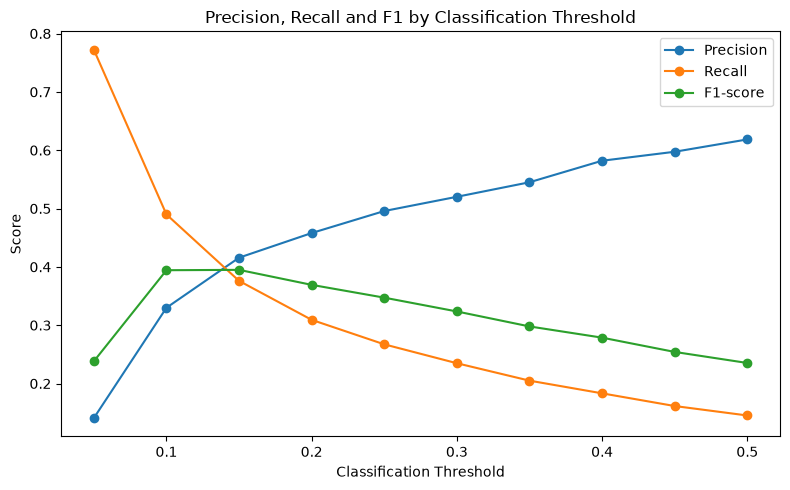

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(threshold_df["threshold"], threshold_df["precision"],
         marker="o", label="Precision")

plt.plot(threshold_df["threshold"], threshold_df["recall"],
         marker="o", label="Recall")

plt.plot(threshold_df["threshold"], threshold_df["f1"],
         marker="o", label="F1-score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 by Classification Threshold")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/threshold_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
best_row = threshold_df.loc[threshold_df["f1"].idxmax()]

print("Best threshold by F1:")
print(best_row)

Best threshold by F1:
threshold    0.150000
precision    0.415781
recall       0.376012
f1           0.394898
Name: 2, dtype: float64


In [36]:
best_threshold = best_row["threshold"]

y_pred_best = (y_prob >= best_threshold).astype(int)

In [37]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Confusion Matrix:
[[26926  1044]
 [ 1233   743]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     27970
           1       0.42      0.38      0.39      1976

    accuracy                           0.92     29946
   macro avg       0.69      0.67      0.68     29946
weighted avg       0.92      0.92      0.92     29946



## Classification Threshold Analysis

The default classification threshold of 0.50 produced high overall accuracy but very low recall for borrowers experiencing financial distress.

Because the target variable is highly imbalanced, multiple probability thresholds were evaluated using precision, recall and F1-score.

Lower thresholds increased the proportion of defaults detected, but also increased false positives. Therefore, the final operating threshold should ultimately depend on the financial cost of false negatives versus false positives and the institution's risk appetite.